In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn joblib plotly -q

print("All libraries installed successfully!")

All libraries installed successfully!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from google.colab import files
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import *

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Dataset uploaded successfully!")
print("Dataset shape:", df.shape)

display(df.head(10))


Saving ai4i2020.csv to ai4i2020 (1).csv
Dataset uploaded successfully!
Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
5,6,M14865,M,298.1,308.6,1425,41.9,11,0,0,0,0,0,0
6,7,L47186,L,298.1,308.6,1558,42.4,14,0,0,0,0,0,0
7,8,L47187,L,298.1,308.6,1527,40.2,16,0,0,0,0,0,0
8,9,M14868,M,298.3,308.7,1667,28.6,18,0,0,0,0,0,0
9,10,M14869,M,298.5,309.0,1741,28.0,21,0,0,0,0,0,0


In [ ]:
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

df = df.drop_duplicates().copy()

df = df.drop(columns=[
    "UDI", "Product ID", "TWF",
    "HDF", "PWF", "OSF", "RNF"
])

df = df[df["Machine failure"].isin([0, 1])]

display(df.describe().round(2))
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
count,10000.0,10000.00,10000.00,10000.00,10000.00,10000.00
mean,300.0,310.01,1538.78,39.99,107.95,0.03
std,2.0,1.48,179.28,9.97,63.65,0.18
min,295.3,305.70,1168.00,3.80,0.00,0.00
25%,298.3,308.80,1423.00,33.20,53.00,0.00
50%,300.1,310.10,1503.00,40.10,108.00,0.00
75%,301.5,311.10,1612.00,46.80,162.00,0.00
max,304.5,313.80,2886.00,76.60,253.00,1.00


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


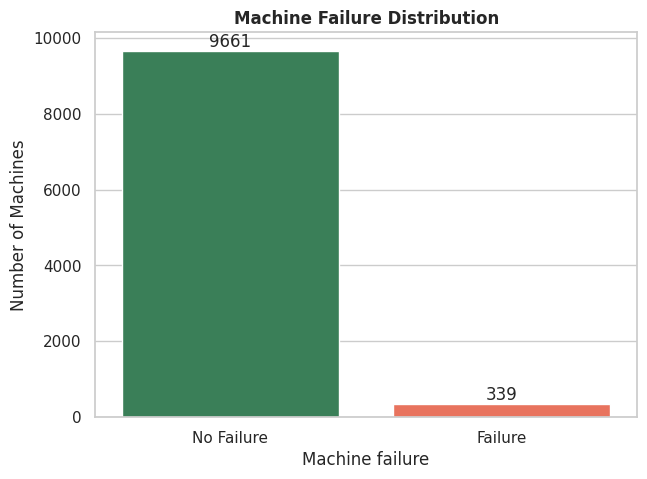

In [ ]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df, x="Machine failure",
    hue="Machine failure",
    palette=["seagreen", "tomato"],
    legend=False
)

for c in ax.containers:
    ax.bar_label(c)

plt.xticks([0, 1], ["No Failure", "Failure"])
plt.title("Machine Failure Distribution", fontweight="bold")
plt.ylabel("Number of Machines")
plt.show()

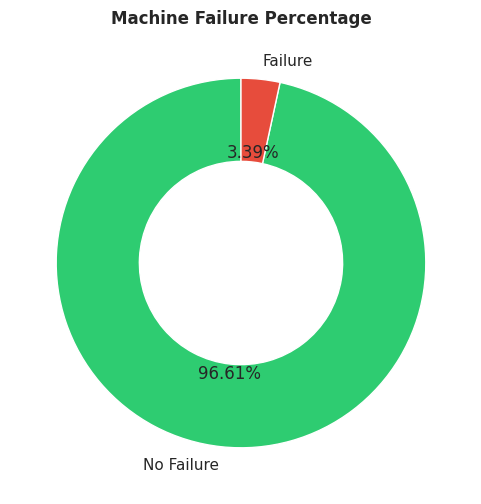

In [ ]:
plt.figure(figsize=(6, 6))

plt.pie(
    df["Machine failure"].value_counts().reindex([0, 1]),
    labels=["No Failure", "Failure"],
    colors=["#2ecc71", "#e74c3c"],
    autopct="%1.2f%%",
    startangle=90,
    wedgeprops={"width": 0.45, "edgecolor": "white"}
)

plt.title("Machine Failure Percentage", fontweight="bold")
plt.show()

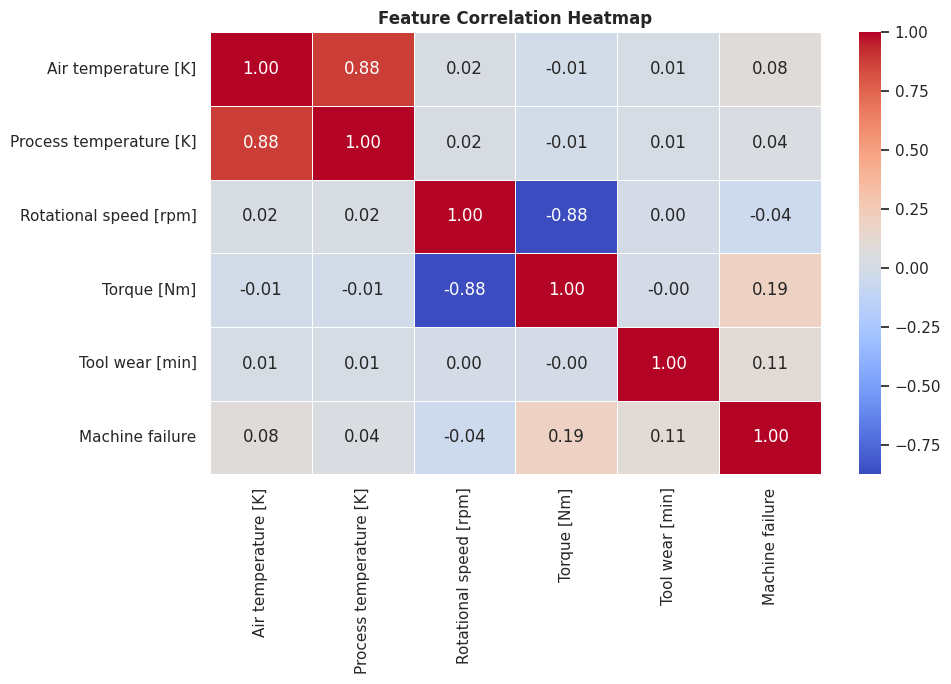

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True, fmt=".2f",
    cmap="coolwarm", linewidths=0.5
)

plt.title("Feature Correlation Heatmap", fontweight="bold")
plt.tight_layout()
plt.show()

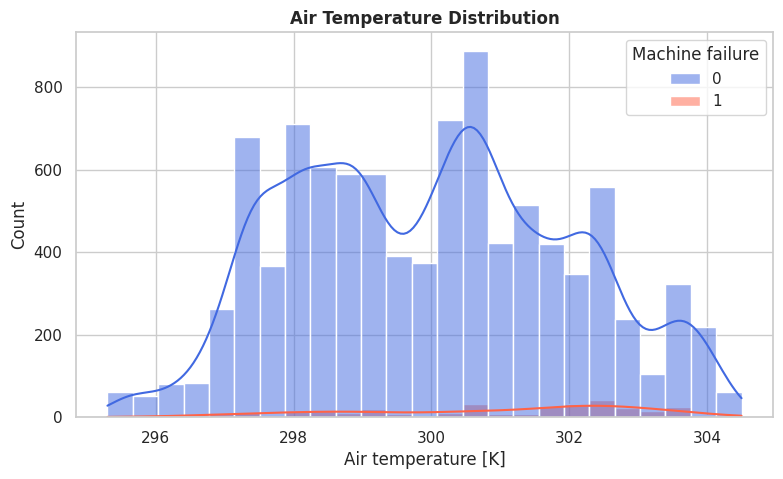

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Air temperature [K]",
    hue="Machine failure",
    bins=25, kde=True,
    palette=["royalblue", "tomato"]
)

plt.title("Air Temperature Distribution", fontweight="bold")
plt.show()

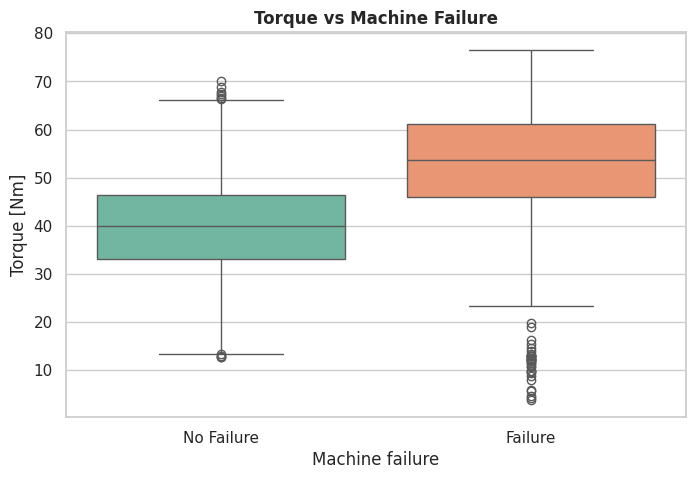

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Machine failure",
    y="Torque [Nm]",
    hue="Machine failure",
    palette="Set2",
    legend=False
)

plt.xticks([0, 1], ["No Failure", "Failure"])
plt.title("Torque vs Machine Failure", fontweight="bold")
plt.show()

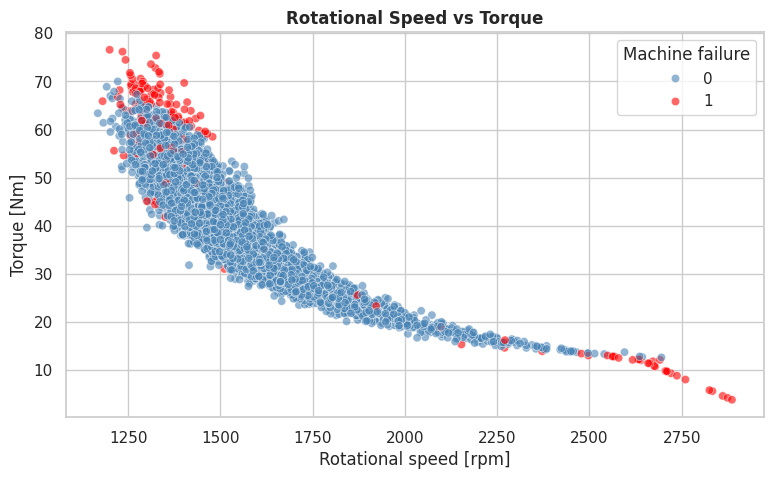

In [ ]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Rotational speed [rpm]",
    y="Torque [Nm]",
    hue="Machine failure",
    palette=["steelblue", "red"],
    alpha=0.6
)

plt.title("Rotational Speed vs Torque", fontweight="bold")
plt.show()

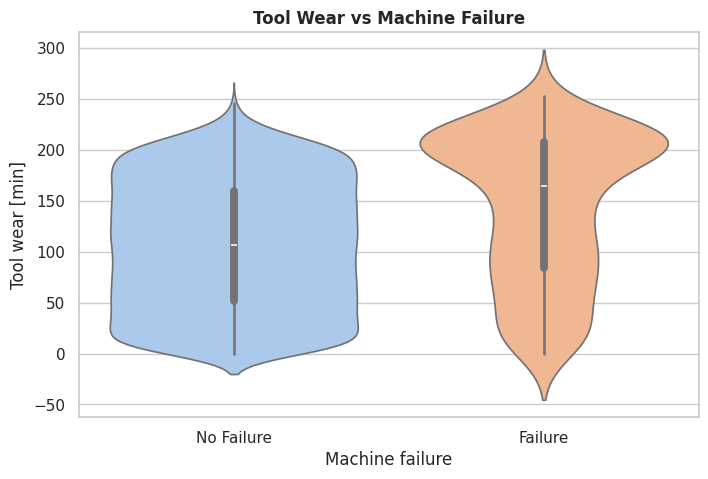

In [ ]:
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=df,
    x="Machine failure",
    y="Tool wear [min]",
    hue="Machine failure",
    palette="pastel",
    legend=False
)

plt.xticks([0, 1], ["No Failure", "Failure"])
plt.title("Tool Wear vs Machine Failure", fontweight="bold")
plt.show()

In [ ]:
FEATURES = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[FEATURES].copy()
y = df["Machine failure"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (8000, 6)
Testing Data: (2000, 6)


In [ ]:
from sklearn.preprocessing import PolynomialFeatures, FunctionTransformer

num = FEATURES[1:]

preprocessor = ColumnTransformer([

    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("features", PolynomialFeatures(
            degree=2,
            interaction_only=True,
            include_bias=False
        )),
        ("scaler", StandardScaler())
    ]), num),

    ("temp_diff", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("difference", FunctionTransformer(
            np.diff, kw_args={"axis": 1}
        )),
        ("scaler", StandardScaler())
    ]), ["Air temperature [K]", "Process temperature [K]"]),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), ["Type"])

])

print("Feature Engineering & Preprocessing Completed!")

Feature Engineering & Preprocessing Completed!


In [ ]:
from sklearn.base import clone

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    )
}

trained = {}

for name, model in models.items():

    pipe = Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)
    trained[name] = pipe

    print(name, "- Training Completed!")

Logistic Regression - Training Completed!
Decision Tree - Training Completed!
Random Forest - Training Completed!


In [ ]:
results = []

for name, model in trained.items():

    pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-Score": f1_score(y_test, pred, zero_division=0)
    })

comparison = pd.DataFrame(results)

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8245,0.1418,0.8235,0.2419
1,Decision Tree,0.9775,0.6949,0.6029,0.6457
2,Random Forest,0.9800,0.9667,0.4265,0.5918


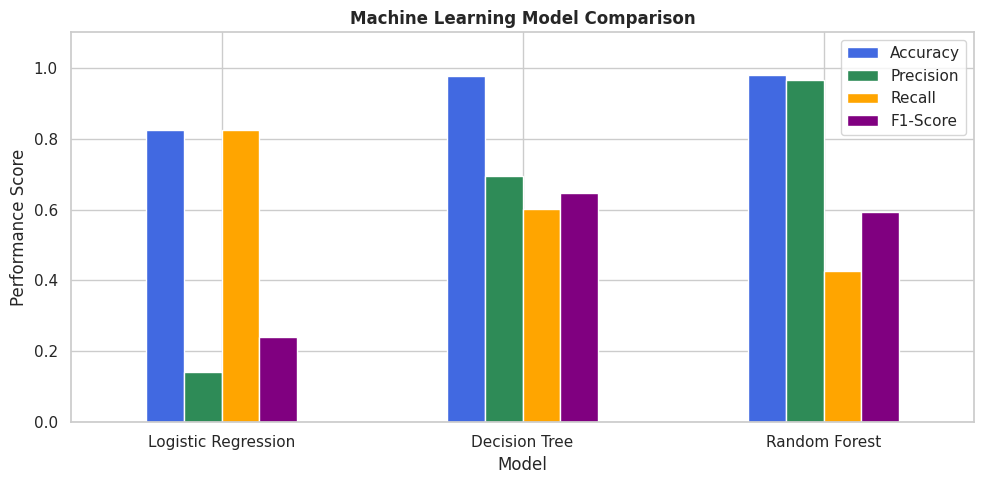

In [ ]:
comparison.set_index("Model").plot(
    kind="bar", figsize=(10, 5),
    color=["royalblue", "seagreen", "orange", "purple"]
)

plt.title("Machine Learning Model Comparison", fontweight="bold")
plt.ylabel("Performance Score")
plt.xticks(rotation=0)
plt.ylim(0, 1.1)
plt.tight_layout()
plt.show()

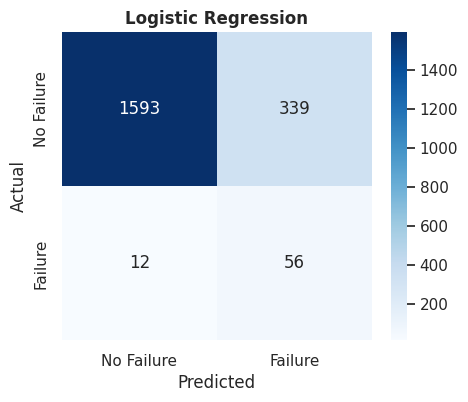

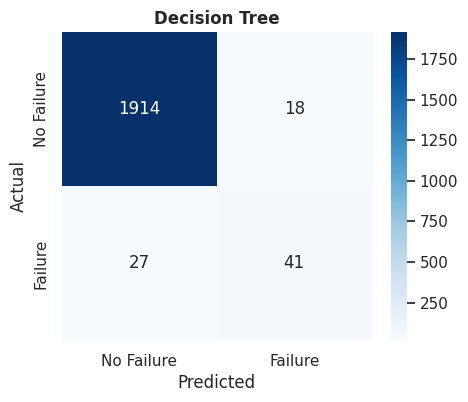

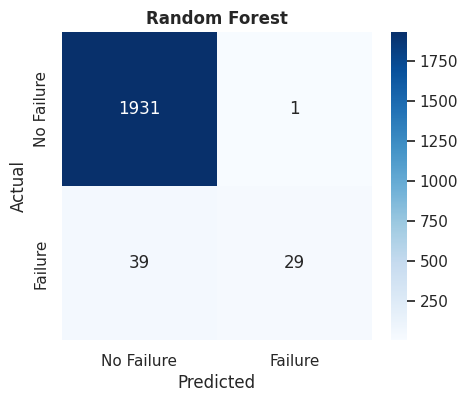

In [ ]:
for name, model in trained.items():

    pred = model.predict(X_test)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        confusion_matrix(y_test, pred, labels=[0, 1]),
        annot=True, fmt="d", cmap="Blues",
        xticklabels=["No Failure", "Failure"],
        yticklabels=["No Failure", "Failure"]
    )

    plt.title(name, fontweight="bold")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [ ]:
cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

cv_results = []

for name, model in trained.items():

    scores = cross_val_score(
        model, X_train, y_train,
        cv=cv, scoring="f1", n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        **{f"Fold {i+1}": s for i, s in enumerate(scores)},
        "Mean F1": scores.mean()
    })

cv_df = pd.DataFrame(cv_results)

display(cv_df.round(4))

,Model,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean F1
0,Logistic Regression,0.2474,0.2196,0.2310,0.2439,0.2310,0.2346
1,Decision Tree,0.6538,0.5393,0.6392,0.6296,0.6170,0.6158
2,Random Forest,0.5974,0.5067,0.5455,0.5250,0.4737,0.5296


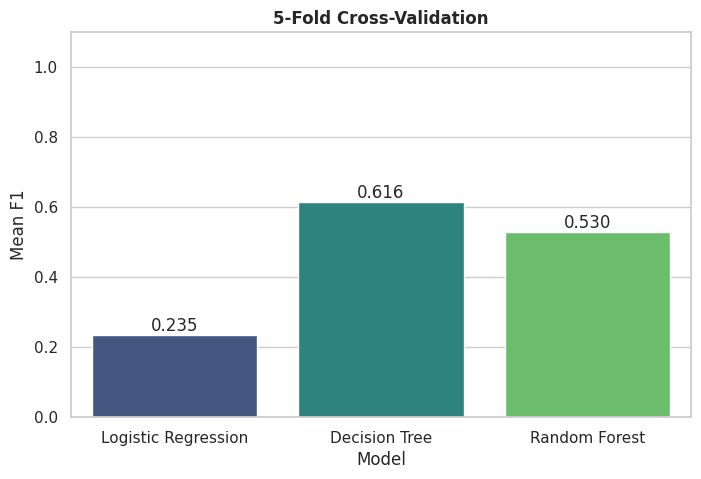

In [ ]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=cv_df, x="Model", y="Mean F1",
    hue="Model", palette="viridis", legend=False
)

for c in ax.containers:
    ax.bar_label(c, fmt="%.3f")

plt.title("5-Fold Cross-Validation", fontweight="bold")
plt.ylim(0, 1.1)
plt.show()

In [ ]:
params = {
    "Logistic Regression": {
        "model__C": [0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"]
    },

    "Decision Tree": {
        "model__max_depth": [5, 10, 15, None],
        "model__min_samples_leaf": [1, 2, 5],
        "model__class_weight": [None, "balanced"]
    },

    "Random Forest": {
        "model__n_estimators": [200, 300],
        "model__max_depth": [15, 25, None],
        "model__min_samples_leaf": [1, 2],
        "model__class_weight": [None, "balanced"]
    }
}

tuned = {}
tuning_results = []

for name, model in trained.items():

    grid = GridSearchCV(
        model,
        params[name],
        cv=cv,
        scoring="f1",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    tuned[name] = grid.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV F1": grid.best_score_,
        "Best Parameters": grid.best_params_
    })

    print(name, "- Tuning Completed!")

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df)

Logistic Regression - Tuning Completed!
Decision Tree - Tuning Completed!
Random Forest - Tuning Completed!


,Model,Best CV F1,Best Parameters
0,Logistic Regression,0.406137,"{'model__C': 10, 'model__class_weight': None}"
1,Decision Tree,0.885591,"{'model__class_weight': None, 'model__max_dept..."
2,Random Forest,0.881915,"{'model__class_weight': None, 'model__max_dept..."


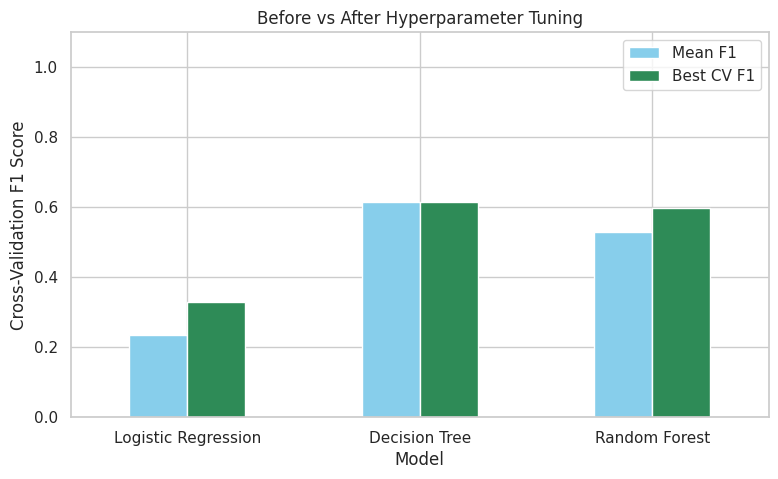

In [ ]:
scores = cv_df[["Model", "Mean F1"]].merge(
    tuning_df[["Model", "Best CV F1"]], on="Model"
)

scores.set_index("Model").plot(
    kind="bar", figsize=(9, 5),
    color=["skyblue", "seagreen"]
)

plt.title("Before vs After Hyperparameter Tuning")
plt.ylabel("Cross-Validation F1 Score")
plt.xticks(rotation=0)
plt.ylim(0, 1.1)
plt.show()

In [ ]:
best_row = tuning_df.loc[tuning_df["Best CV F1"].idxmax()]

best_name = best_row["Model"]
best_model = tuned[best_name]

pred = best_model.predict(X_test)
prob = best_model.predict_proba(X_test)[:, 1]

final_results = pd.DataFrame([{
    "Model": best_name,
    "Accuracy": accuracy_score(y_test, pred),
    "Precision": precision_score(y_test, pred, zero_division=0),
    "Recall": recall_score(y_test, pred, zero_division=0),
    "F1-Score": f1_score(y_test, pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, prob)
}])

print("=" * 45)
print("        BEST MODEL PERFORMANCE")
print("=" * 45)

print("Best Model :", best_name)

for metric in ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]:
    print(f"{metric:12}: {final_results[metric].iloc[0]*100:.2f}%")

print("=" * 45)

display(final_results.round(4))

print(classification_report(y_test, pred, zero_division=0))

        BEST MODEL PERFORMANCE
Best Model : Decision Tree
Accuracy    : 99.30%
Precision   : 95.00%
Recall      : 83.82%
F1-Score    : 89.06%
ROC-AUC     : 94.95%


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree,0.993,0.95,0.8382,0.8906,0.9495


              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1932
           1       0.95      0.84      0.89        68

    accuracy                           0.99      2000
   macro avg       0.97      0.92      0.94      2000
weighted avg       0.99      0.99      0.99      2000



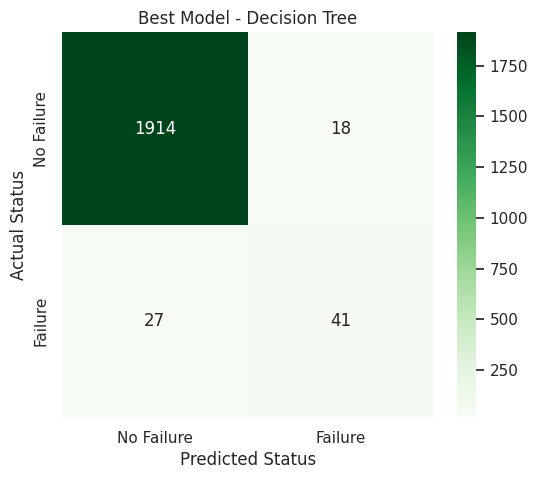

In [ ]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    confusion_matrix(y_test, pred, labels=[0, 1]),
    annot=True, fmt="d", cmap="Greens",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.title("Best Model - " + best_name)
plt.xlabel("Predicted Status")
plt.ylabel("Actual Status")
plt.show()

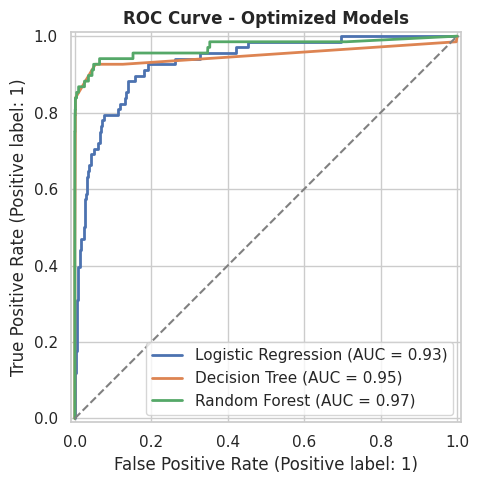

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

for name, model in tuned.items():
    RocCurveDisplay.from_estimator(
        model, X_test, y_test,
        name=name, ax=ax, linewidth=2
    )

plt.plot([0, 1], [0, 1], "--", color="gray")
plt.title("ROC Curve - Optimized Models", fontweight="bold")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

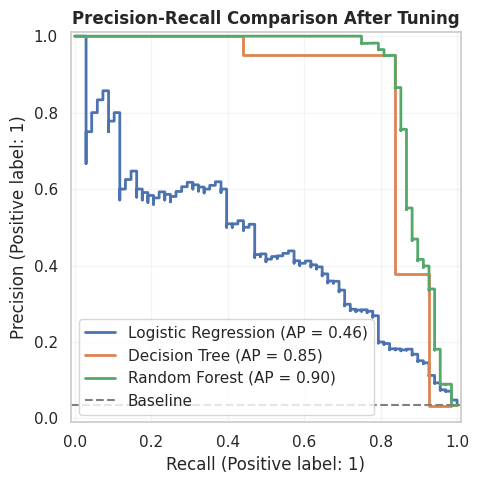

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

for name, model in tuned.items():
    PrecisionRecallDisplay.from_estimator(
        model, X_test, y_test,
        name=name, ax=ax, linewidth=2
    )

plt.axhline(y_test.mean(), color="gray", linestyle="--", label="Baseline")
plt.title("Precision-Recall Comparison After Tuning", fontweight="bold")
plt.legend(loc="best")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [ ]:
new_machine = pd.DataFrame([{
    "Type": "M",
    "Air temperature [K]": 300,
    "Process temperature [K]": 310,
    "Rotational speed [rpm]": 1500,
    "Torque [Nm]": 40,
    "Tool wear [min]": 100
}])

prediction = best_model.predict(new_machine)[0]
probability = best_model.predict_proba(new_machine)[0, 1]

print("Model:", best_name)
print("Machine Failure:", "Yes" if prediction == 1 else "No")
print("Failure Probability:", round(probability * 100, 2), "%")

Model: Decision Tree
Machine Failure: No
Failure Probability: 0.12 %


In [ ]:
joblib.dump(best_model, "machine_model.joblib")

comparison.to_csv("model_comparison.csv", index=False)
cv_df.to_csv("cross_validation.csv", index=False)
tuning_df.to_csv("tuning_results.csv", index=False)
final_results.to_csv("final_results.csv", index=False)
df.to_csv("cleaned_dataset.csv", index=False)

with open("requirements.txt", "w") as f:
    f.write(
        f"scikit-learn=={sklearn.__version__}\n"
        f"numpy=={np.__version__}\n"
        f"pandas=={pd.__version__}\n"
        f"joblib=={joblib.__version__}\n"
        "streamlit\nplotly\n"
    )

print("All files saved successfully!")

All files saved successfully!


In [ ]:
import zipfile

output = [
    "machine_model.joblib",
    "model_comparison.csv",
    "cross_validation.csv",
    "tuning_results.csv",
    "final_results.csv",
    "cleaned_dataset.csv",
    "requirements.txt"
]

with zipfile.ZipFile("Machine_Failure_Project.zip", "w") as z:
    for file in output:
        z.write(file)

files.download("Machine_Failure_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>